1 Nombre de canals
2 Nombre de classes


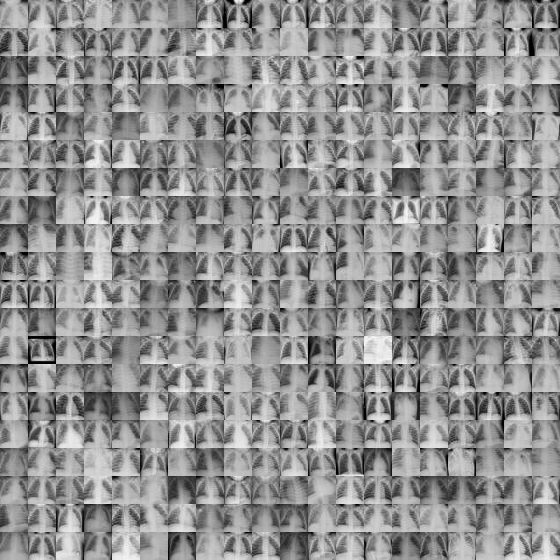

In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# preprocessing
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5]),
    transforms.Lambda(torch.flatten)
])

from medmnist import PneumoniaMNIST
from medmnist import INFO, Evaluator

dataset_train = PneumoniaMNIST(split="train", transform = data_transform, download=True, size=28)
dataset_valid = PneumoniaMNIST(split="val", transform = data_transform, download=True, size=28)
dataset_test = PneumoniaMNIST(split="test", transform = data_transform, download=True, size=28)

data_flag = 'pneumoniamnist'

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

print(f"{n_channels} Nombre de canals")
print(f"{n_classes} Nombre de classes")

dataset_train.montage(20)


In [4]:
batch_size = 64

train_dataloader = DataLoader(dataset_train, batch_size=batch_size, drop_last=False, shuffle=True)
val_dataloader = DataLoader(dataset_valid, batch_size=batch_size, drop_last=False, shuffle=False)
test_dataloader = DataLoader(dataset_test, batch_size=batch_size, drop_last=False, shuffle=False)

for X, y in train_dataloader:
    print(f"Shape of X [N, C]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([64, 1]) torch.int64
Shape of X [N, C]: torch.Size([64, 784])
Shape of y: torch.Size([

In [5]:
class TinyMLP(nn.Module):
    def __init__(self):
        super(TinyMLP, self).__init__()
        self.fc1 = nn.Linear(784, 128)   # 28*28 = 784 entrées -> 128 unités cachées
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 2)     # 2 classes en sortie
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.softmax(x)
        return x

In [10]:
my_model = TinyMLP()
optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-4)
my_loss = nn.CrossEntropyLoss()
device = "cpu"
my_model.to(device)

loss_train = []
loss_valid = []

for epoch in tqdm(range(100)):

    my_model.train()
    loss_total = 0
    for batch, (X, y) in enumerate(train_dataloader):
        X, y = X.to(device), y.squeeze().long().to(device)

        # Compute prediction error
        pred = my_model(X)
        loss = my_loss(pred, y)
        loss_total += loss.item()

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    loss_train.append(loss_total / len(train_dataloader))

    my_model.eval()
    loss_total = 0                       # à remettre à zéro
    with torch.no_grad():                # pas de gradients en validation
        for batch, (X, y) in enumerate(val_dataloader):
            X, y = X.to(device), y.squeeze().long().to(device)

            # Compute prediction error
            pred = my_model(X)
            loss = my_loss(pred, y)
            loss_total += loss.item()

    loss_valid.append(loss_total / len(val_dataloader))

100%|██████████| 100/100 [00:20<00:00,  4.93it/s]


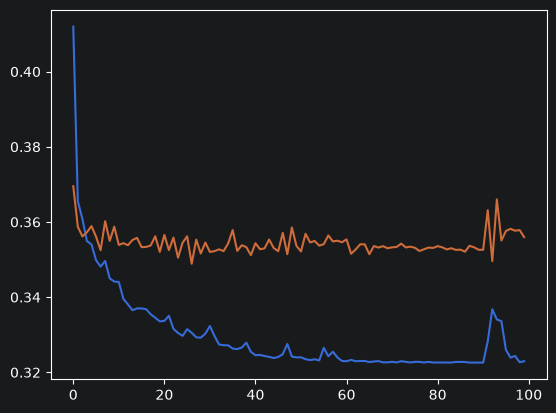

In [11]:
plt.plot(loss_train) #courbe bleu
plt.plot(loss_valid) #courbe orange